Copyright (c) European Space Agency, 2026.  
This file is subject to the terms and conditions defined in file 'LICENCE.txt',   
which is part of this source code package. No part of the package, including  
this file, may be copied, modified, propagated, or distributed except according to   
the terms contained in the file ‘LICENCE.txt’.

# Analysis of Gaia DR4 astrometric timeseries of `Gaia BH3`
## This notebook was prepared by the Gaia collaboration. If you find it useful for your research or otherwise, please follow these acknowledgement and citation instructions: https://gea.esac.esa.int/archive/documentation/GDR3/Miscellaneous/sec_credit_and_citation_instructions/

## Content of this notebook  
This notebook demonstrates the following steps:
- Load the timeseries data of the Gaia astrometric instrument. The data are part of the Gaia DR4 pre-release, see https://www.cosmos.esa.int/web/gaia/dr4-prerelease 
- Fit an orbit to the astrometric data and determine the black hole's mass.

## Environment installation
- For local execution, one can use the environment.yml file included in this repository to create a python environment using conda with the necessary dependencies for code execution:  
`conda env create --file gaia-bhthree/environment.yml`

### Imports

In [1]:
from collections import OrderedDict
import copy
import logging
import os
import urllib.request
import zipfile
import glob

from astropy.time import Time
import astropy.units as u
from IPython.display import display, Markdown
import matplotlib.pyplot as pl
import numpy as np
import pandas as pd
from astropy.table import Table


from kepmodel.astro import AstroModel as AstrometricModel
from pystrometry.pystrometry import convert_from_angular_to_linear, pjGet_m2, MS_kg, MJ_kg
from pystrometry import gaia_astrometry as gaia_astrometry_plotter
import spleaf

from gaiasupdate.epoch_astrometry import GaiaEpochAstrometryArchive


logger = logging.getLogger()
logger.setLevel(logging.INFO)

Matplotlib is building the font cache; this may take a moment.


Maintenance with possible short-time disconnections: 29 June 2026 18:00–20:00 CEST


### Folder and constants definition

In [2]:
base_dir = os.getcwd()
data_dir = os.path.join(base_dir)
plot_dir = os.path.join(base_dir)

DR4_REFERENCE_EPOCH = Time('2017.5', format='jyear', scale='tcb')

## Download astrometric-timeseries data

In [3]:
# URL of the file to download
url = "https://anonftp.cosmos.esa.int/pub/GAIA_PUBLIC_DATA/Gaia_DR4/dr4-prerelease/gaia-dr4-prerelease-epoch-astrometry_2026-06-26.zip"

local_dir = os.getcwd()

# Define download path
download_path = os.path.join(local_dir, 'downloaded_file.zip')
extract_path = os.path.join(local_dir, 'extracted_files')

if not os.path.isfile(download_path):

    # Download the file
    urllib.request.urlretrieve(url, os.path.basename(download_path))
    logging.info(f"Downloaded {url} to {os.path.basename(download_path)}")

with zipfile.ZipFile(download_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
logging.info(f"Extracted {os.path.basename(download_path)} to {os.path.basename(extract_path)}")


epoch_astrometry_file = glob.glob(os.path.join(extract_path, '*.xml'))[0]
logging.info(f"Found epoch astrometry file: {os.path.basename(epoch_astrometry_file)}")

table = Table.read(epoch_astrometry_file, format="votable")
epoch_astrometry = table.to_pandas()
logging.info(f"File contains data for {epoch_astrometry['source_id'].nunique()} unique sources.\n")

INFO:root:Extracted downloaded_file.zip to extracted_files
INFO:root:Found epoch astrometry file: GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml
INFO:root:File contains data for 12 unique sources.



## Select data corresponding to target of interest

### Source parameters

In [4]:

name_dict = {'Gaia BH3': 4318465066420528000,
    'HD 114762': 3937211745905473024,
    'Gaia-4': 1457486023639239296}


source_id = name_dict['Gaia BH3'] # for Gaia BH3
# source_id = name_dict['HD 114762'] 
# source_id = name_dict['Gaia-4'] 

m1_MS = 0.76  # Primary star mass for Gaia BH3
target_ra_deg = 294.8278502411 # Right Ascension for Gaia BH3
target_dec_deg = 14.9309190720 # Declination for Gaia BH3


epoch_astrometry_bh3 = epoch_astrometry[epoch_astrometry['source_id'] == source_id]

## use `gaiasupdate` to load epoch_astrometry data and prepare it for analysis

In [5]:
# instantiate object
ea = GaiaEpochAstrometryArchive.from_dataframe(epoch_astrometry_bh3)

# use only data used by the Gaia DR4 core astrometric solution
ea.epoch_data = ea.epoch_data.epochastrometryarchive.filter_on_used_by_agis()

# sort by increasing time
ea.epoch_data.epochastrometryarchive.sort_by_column('obs_time_tcb')

# set auxiliary fields
ea.epoch_data.epochastrometryarchive.set_relative_time() # sets 'relative_time_year','relative_time_day'
ea.epoch_data = ea.epoch_data.epochastrometryarchive.set_scan_angle_derived_columns() # sets 'sin_theta', 'cos_theta', 'sin_theta_time', 'cos_theta_time'

INFO:root:Filter on column obs_time_tcb!=null removed 0 entries.
/Users/sahlmann/software/mambaforge/envs/gaia-bhthree-prerelease/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)
/Users/sahlmann/software/mambaforge/envs/gaia-bhthree-prerelease/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)
/Users/sahlmann/software/mambaforge/envs/gaia-bhthree-prerelease/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)
/Users/sahlmann/software/mambaforge/envs/gaia-bhthree-prerelease/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)
INFO:root:Filter on used_by_agis_al==Tr

In [6]:
ea.epoch_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 42 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   solution_id                558 non-null    int64  
 1   source_id                  558 non-null    int64  
 2   transit_id                 558 non-null    int64  
 3   ra0                        558 non-null    float64
 4   dec0                       558 non-null    float64
 5   agis_source_excess_noise   558 non-null    float32
 6   obs_time_tcb               558 non-null    int64  
 7   obs_time_bary_corr         558 non-null    float32
 8   scan_pos_angle             558 non-null    float64
 9   zeta                       558 non-null    float32
 10  parallax_factor_al         558 non-null    float32
 11  parallax_factor_ac         558 non-null    float32
 12  colour_factor_al           558 non-null    float64
 13  colour_factor_ac           558 non-null    object 

In [7]:

gaia_astrometry = ea.epoch_data.copy()

# set or rename fields for compatibility with the orbit fitting code
gaia_astrometry['transitid'] = gaia_astrometry['transit_id']
gaia_astrometry['mjd'] = Time(gaia_astrometry['relative_time_year']+DR4_REFERENCE_EPOCH.jyear, format='jd', scale='tcb').mjd
gaia_astrometry['cpsi_obs'] = gaia_astrometry['cos_theta']
gaia_astrometry['spsi_obs'] = gaia_astrometry['sin_theta']
gaia_astrometry['ppfact_obs'] = gaia_astrometry['parallax_factor_al']
gaia_astrometry['da_mas'] = gaia_astrometry['centroid_pos_al']
gaia_astrometry['sigma_da_mas'] = gaia_astrometry['centroid_pos_error_al']

### Display a few data records

In [8]:
columns_to_show = 'source_id transit_id component_index relative_time_year centroid_pos_al centroid_pos_error_al parallax_factor_al scan_pos_angle'.split()
display(gaia_astrometry[columns_to_show].sample(10, random_state=1).sort_values('relative_time_year'))

,source_id,transit_id,component_index,relative_time_year,centroid_pos_al,centroid_pos_error_al,parallax_factor_al,scan_pos_angle
29,4318465066420528000,22159827441309232,6,-2.578467,379.177179,0.071610,-0.459423,-5.782776
65,4318465066420528000,26684893047879248,7,-2.354421,-293.346261,0.116041,-0.213787,-134.155307
245,4318465066420528000,61702852954182073,7,-0.620584,7.133463,0.068662,0.615358,-68.393186
323,4318465066420528000,81048724350046919,5,0.337284,-51.568517,0.077617,-0.700534,26.648937
346,4318465066420528000,82490273693622584,1,0.408653,-19.478528,0.097264,0.518362,-71.280674
360,4318465066420528000,88996791291101892,6,0.730811,87.727407,0.071238,-0.620023,-135.594453
440,4318465066420528000,98103120972406823,7,1.181704,-142.031012,0.102571,-0.416509,49.073607
474,4318465066420528000,103266346797774320,6,1.437330,-13.948028,0.083533,0.387568,-72.663240
530,4318465066420528000,120150603084362450,8,2.273327,-311.987048,0.085388,-0.695090,40.014342
547,4318465066420528000,121996985218154856,7,2.364738,-62.000964,0.093625,0.647710,-66.573439


## Fit the standard astrometric model 
The standard astrometric model for the motion $w_\mathrm{ss}$ of a single star can be written as
\begin{equation}
w_\mathrm{ss} = ( \Delta\alpha^{\star} + \mu_{\alpha^\star} \, t ) \, \sin \psi + ( \Delta\delta + \mu_\delta \, t ) \, \cos \psi + \varpi \, f_\varpi, 
\end{equation}
where $\Delta\alpha^{\star} = \Delta\alpha \cos{\delta}$ and $\Delta \delta$ are small offsets in equatorial coordinates from a fixed reference point ($\alpha_0$, $\delta_0$), $\mu_{\alpha^\star}$ and $\mu_\delta$ are proper motions in these coordinates, $t$ is time since the Gaia DR4 reference time J2017.5, $\varpi$ is the parallax, $f_\varpi$ is the parallax factor, and $\psi$ is the instantaneous Gaia scan angle. For more details see Section 3 of https://www.aanda.org/articles/aa/full_html/2023/06/aa44161-22/aa44161-22.html and https://www.aanda.org/articles/aa/full_html/2023/06/aa43969-22/aa43969-22.html

We use the open-source python package [kepmodel](https://obswww.unige.ch/~delisle/kepmodel/doc/) (Delisle & Ségransan, 2022, A&A, 667, A172), which allows us to model radial velocity and/or astrometric time series including Keplerian orbits.

In [9]:
include_jitter_term = False

if include_jitter_term:
    astrometric_jitter_value = 0.05
else:
    astrometric_jitter_value = 0.0
    
# set up the single-star model with an additional jitter term of 0.05 mas
single_star_model = AstrometricModel(gaia_astrometry['relative_time_day'].values, 
                                     gaia_astrometry['centroid_pos_al'].values, 
                                     gaia_astrometry['cpsi_obs'].values, 
                                     gaia_astrometry['spsi_obs'].values, 
                                     err=spleaf.term.Error(gaia_astrometry['centroid_pos_error_al'].values),
                                     jit=spleaf.term.Jitter(astrometric_jitter_value))
    
# define the linear parameters
single_star_model.add_lin(gaia_astrometry['spsi_obs'].values, 'ra')
single_star_model.add_lin(gaia_astrometry['cpsi_obs'].values, 'dec')
single_star_model.add_lin(gaia_astrometry['parallax_factor_al'].values, 'parallax')
single_star_model.add_lin(gaia_astrometry['relative_time_year'].values * gaia_astrometry['spsi_obs'].values, 'mura')
single_star_model.add_lin(gaia_astrometry['relative_time_year'].values * gaia_astrometry['cpsi_obs'].values, 'mudec')

# add jitter term
if include_jitter_term:
    single_star_model.fit_param += ['cov.jit.sig']

# perform the fit
single_star_model.fit()

print("Best-fit single-star model parameters: (the units are mas and mas/year)")
single_star_model.show_param()

Best-fit single-star model parameters: (the units are mas and mas/year)
Parameter                        Value     Error       
lin.ra                         0.71001  ±  0.00506     
lin.dec                        0.26549  ±  0.00452     
lin.parallax                   0.98329  ±  0.00623     
lin.mura                     -30.94602  ±  0.00362     
lin.mudec                   -148.54974  ±  0.00281     


## Fit the Keplerian astrometric model 

Using [kepmodel](https://obswww.unige.ch/~delisle/kepmodel/doc/), we first compute the periodogram of the residuals of the standard-model fit. With the estimated period we initialise a Keplerian model and fit it to the data.

The astrometric motion corresponding to a Keplerian orbit of a binary system has generally seven independent parameters. These
are the period $P$, the epoch of periastron passage $T_0$, the eccentricity $e$, the inclination $i$, the ascending node $\Omega$, the argument of periastron $\omega$, and the semi-major axis of the photocentre $a_0$. The Thiele-Innes coefficients $A, B, F, G$, which linearise part of the equations, are defined as
\begin{eqnarray}
%\begin{split}
% \begin{array}{ll}
A &=&  \ \ \, a_0 \; (\cos \omega \cos \Omega - \sin \omega \sin \Omega \cos i)   \\
B &=&  \ \ \, a_0 \; (\cos \omega \sin \Omega + \sin \omega \cos \Omega \cos i)  \\
F &=& -a_0 \; (\sin \omega \cos \Omega + \cos \omega \sin \Omega \cos i)  \\
G &=&  -a_0 \; (\sin \omega \sin \Omega - \cos \omega \cos \Omega \cos i) 
% \end{array}
%\end{split}
\end{eqnarray}

The elliptical rectangular coordinates $X$ and $Y$ are functions of eccentric anomaly $E$ and eccentricity: 
\begin{eqnarray}
E - e \sin E &=& \frac{2\pi}{P} (t-T_0)\\
X &=& \cos E - e\\
Y &=& \sqrt{1-e^2} \sin E
\end{eqnarray}

The single Keplerian model $w_\mathrm{k1}$ can then be written as 
\begin{equation}
w_\mathrm{k1} = (B \, X + G \, Y) \sin \psi + (A \, X + F \, Y) \cos \psi.
\end{equation}

The combined model $w^\mathrm{(model)}$ for the Gaia along-scan abscissa is
\begin{equation}
\begin{split}
w^\mathrm{(model)} =&\, w_\mathrm{ss} + w_\mathrm{k1} \\
 =&\, ( \Delta\alpha^{\star} + \mu_{\alpha^\star} \, t ) \, \sin \psi + ( \Delta\delta + \mu_\delta \, t ) \, \cos \psi + \varpi \, f_\varpi \\
 &+\, (B \, X + G \, Y) \sin \psi + (A \, X + F \, Y) \cos \psi.
\end{split}\end{equation}


More details are given in Section 3 of https://www.aanda.org/articles/aa/full_html/2023/06/aa44161-22/aa44161-22.html and in https://www.aanda.org/articles/aa/full_html/2023/06/aa43969-22/aa43969-22.html

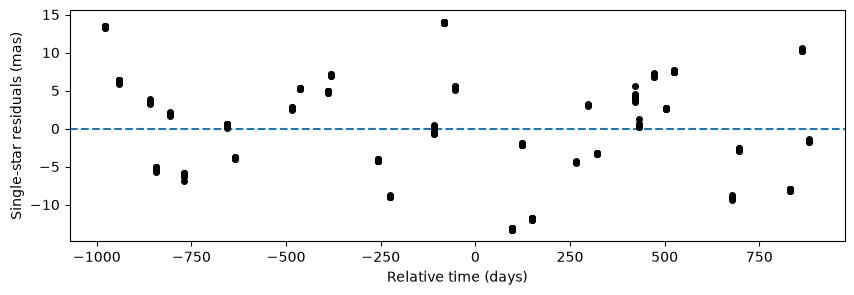

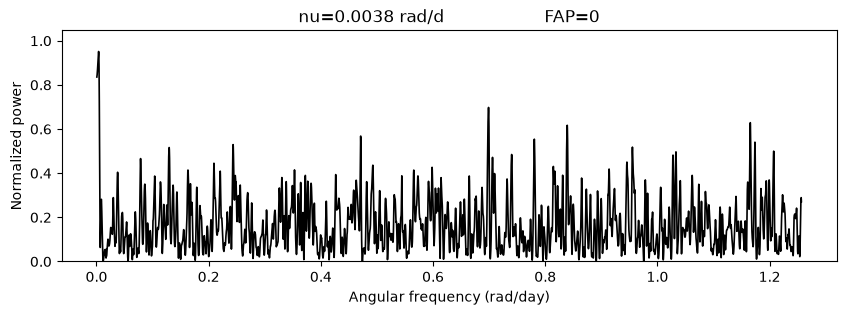

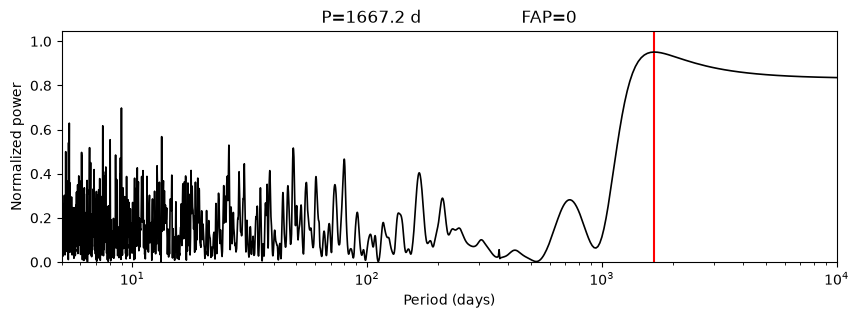

In [10]:
model = copy.deepcopy(single_star_model)

# Periodogram settings 
Pmin = 5
Pmax = 10000
nfreq = 10000
nu0 = 2 * np.pi / Pmax
dnu = (2 * np.pi / Pmin - nu0) / (nfreq - 1)

# plot the single-star residuals
resisuals = model.residuals()
res_err = np.sqrt(model.cov.A)
pl.figure(figsize=(10, 3))
pl.errorbar(model.t, resisuals, yerr=res_err, fmt='o', ecolor='0.7', ms=4, color='k')
pl.xlabel(f'Relative time (days)')
pl.ylabel('Single-star residuals (mas)')
pl.axhline(ls='--')
pl.show()    

# compute periodogram
nu, power = model.periodogram(nu0, dnu, nfreq)

# convert from angular frequency to period
P = 2 * np.pi / nu

# identify highest peak and compute false-alarm probability (FAP)
kmax = np.argmax(power)
faplvl = model.fap(power[kmax], nu.max())

# plot periodogram as a function of frequency
pl.figure(figsize=(10, 3))
pl.plot(nu, power, 'k', lw=1.2)
pl.ylim(0, 1.1 * power.max())
pl.xlabel('Angular frequency (rad/day)')
pl.ylabel('Normalized power')
pl.title(f'nu={nu[kmax]:.4f} rad/d' + 20*' ' + f'FAP={faplvl:.2g}')
pl.show()

# plot periodogram as a function of period
pl.figure(figsize=(10, 3))
pl.plot(2 * [P[kmax]], [0, 1.1 * power.max()], 'r')
pl.plot(P, power, 'k', lw=1.2, rasterized=True)
pl.xlim(Pmin, Pmax)
pl.ylim(0, 1.1 * power.max())
pl.xscale('log')
pl.xlabel('Period (days)')
pl.ylabel('Normalized power')
pl.title(f'P={P[kmax]:.1f} d' + 20*' ' + f'FAP={faplvl:.2g}')
pl.show()

## Fit the Keplerian model

In [11]:
keplerian_model = copy.deepcopy(model)

print(f'Adding a Keplerian with period {P[kmax]:.1f} days to model.\n')

keplerian_model.add_keplerian_from_period(P[kmax])

# fit the new model
keplerian_model.fit()

print(f"Best-fit parameter (Thiele-Innes coefficients)")
keplerian_model.show_param()

# print('Change orbital parameter set:')
param = ['P', 'Tp', 'as', 'e', 'w', 'i', 'bigw']
keplerian_model.set_keplerian_param(f'0', param=param)

print(f"Best-fit parameter (Campbell elements)\nkep.0.P is the period in days, kep.0.as is the semimajor axis in milli-arcseconds\n")
keplerian_model.show_param()    

Adding a Keplerian with period 1667.2 days to model.

Best-fit parameter (Thiele-Innes coefficients)
Parameter                        Value     Error       
lin.ra                          3.4304  ±  0.0424      
lin.dec                         2.5298  ±  0.0587      
lin.parallax                   1.65980  ±  0.00652     
lin.mura                      -28.3435  ±  0.0525      
lin.mudec                    -155.1704  ±  0.0851      
kep.0.P                         4183.7  ±  72.1        
kep.0.M0 [deg]                 339.187  ±  0.368       
kep.0.e                        0.72782  ±  0.00353     
kep.0.TIA                       2.4222  ±  0.0374      
kep.0.TIB                       10.560  ±  0.124       
kep.0.TIF                       20.547  ±  0.297       
kep.0.TIG                      -16.909  ±  0.214       
Best-fit parameter (Campbell elements)
kep.0.P is the period in days, kep.0.as is the semimajor axis in milli-arcseconds

Parameter                        Value     Error 

## Compute the mass of the black hole

In [12]:
keplerian_parameters = {}
for i, key in enumerate(keplerian_model.keplerian['0']._param):
    keplerian_parameters[key] = keplerian_model.keplerian['0']._par[i]

linear_parameters = {}
for i, key in enumerate(keplerian_model._lin_name):
    linear_parameters[key] = keplerian_model._lin_par[i]

a_m = convert_from_angular_to_linear(keplerian_parameters['as'], linear_parameters['parallax'])
m2_kg = pjGet_m2(m1_MS * MS_kg, a_m, keplerian_parameters['P'])
m2_MS = m2_kg / MS_kg
mass_function = keplerian_parameters['as']**3 * (u.year.to(u.day))**2 / (keplerian_parameters['P']**2 * linear_parameters['parallax']**3)

display(Markdown(f'## <strong>Results from astrometry only:</strong>'))
display(Markdown(f'## <strong>The mass function value is {mass_function:.2f} solar masses</strong>'))
display(Markdown(f'## <strong>With a primary mass of {m1_MS} solar masses, the companion has a mass of {m2_MS:.2f} solar masses</strong><br/>'))

## <strong>Results from astrometry only:</strong>

## <strong>The mass function value is 33.21 solar masses</strong>

## <strong>With a primary mass of 0.76 solar masses, the companion has a mass of 34.68 solar masses</strong><br/>

## Create orbit model and display it together with the Gaia measurements

We use plotting tools provided by the open-source python package [pystrometry](https://github.com/Johannes-Sahlmann/pystrometry) (https://zenodo.org/records/10839734), which supports the analysis of high-precision astrometry timeseries. 

## <strong>The five figure panels below show the following (for a detailed description see https://www.aanda.org/articles/aa/full_html/2023/06/aa44161-22/F12.html):
Top left: Parallax and proper motion of the source projected on the sky  
Bottom left: On-sky orbital signature relative to the system's barycentre   
Top right: Orbital signature relative to the system barycentre as a function of time  
Middle right: Aggregated residuals as a function of time  
Bottom right: Individual residuals as a function of time </strong>

++++++++++++++++++++++++++++++
System parameters:
Distance is 602.5 pc 	 Parallax = 1.7 mas
Primary   mass = 0.760 Msol 	 = 796.150 Mjup
Secondary mass = 34.684 Msol 	 = 36334.010 Mjup 	 = 11547980.491 MEarth
Mass ratio q=m2/m1 = 45.637153
a1_mas    = 27.110, a_rel_mas = 27.704, a_rel_au = 16.691
Inclination  110.5 deg
Period is   4183.7 day 	 Eccentricity = 0.728
omega = 78.2 deg, OMEGA = 136.4 deg, T_periastron = 53994.6 day
RV semi-amplitude of primary = 57994.472 m/s



/Users/sahlmann/software/mambaforge/envs/gaia-bhthree-prerelease/lib/python3.12/site-packages/pystrometry/gaia_astrometry.py:231: FutureWarning: The provided callable <built-in function min> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  min_max_time = groups.agg([min, max])[self._time_field]
/Users/sahlmann/software/mambaforge/envs/gaia-bhthree-prerelease/lib/python3.12/site-packages/pystrometry/gaia_astrometry.py:231: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  min_max_time = groups.agg([min, max])[self._time_field]
/Users/sahlmann/software/mambaforge/envs/gaia-bhthree-prerelease/lib/python3.12/site-packages/pystrometry/gaia_astrometry.py:231: FutureWarning: The provided call

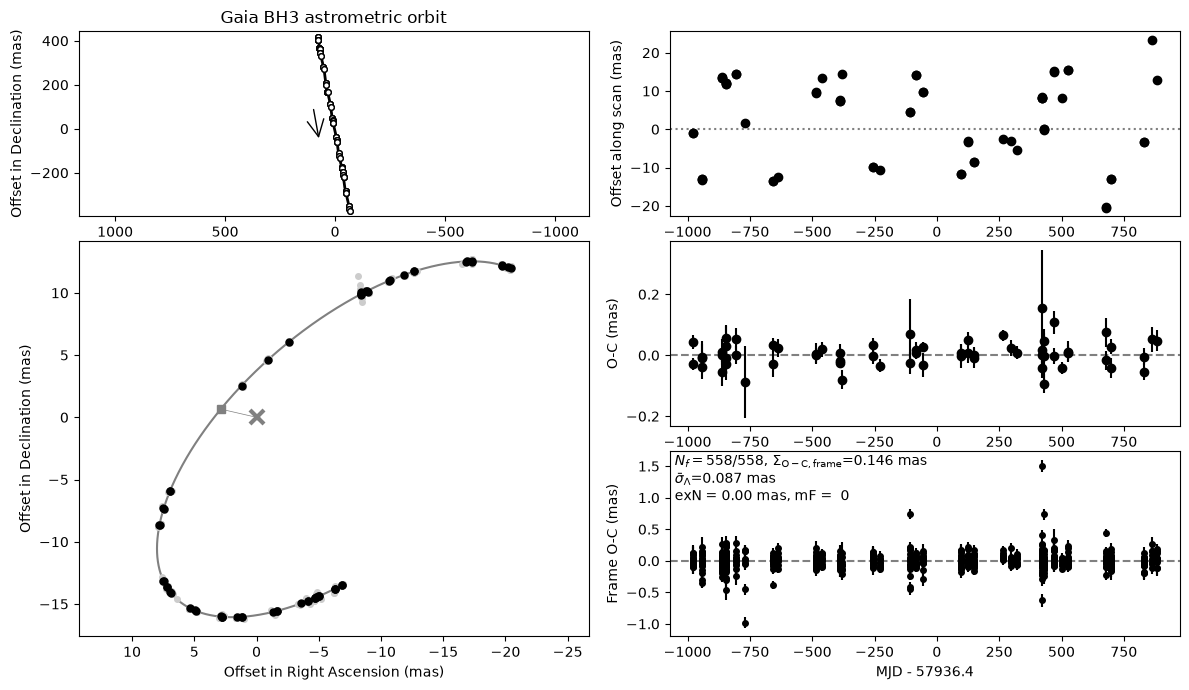

INFO:root:Saved figure as /Users/sahlmann/code/github/esa/gaia-bhthree/1d_summary_4318465066420528000_0.png


In [13]:
# A helper function for plotting
def plot_astrometry(astrometry_timeseries, parameter_df, plot_dir, reference_time, model_name):
    """Make a figure showing the model and the data."""
    
    source_id = parameter_df.loc[0, 'source_id']

    iad = gaia_astrometry_plotter.GaiaValIad.from_dataframe(astrometry_timeseries, source_id, 'source_id')

    iad._mjd_field = 'mjd'
    iad.time_column = 'relative_time_year'
    iad.set_reference_time(reference_time)

    parameter_dict = parameter_df[parameter_df['source_id'] == source_id].iloc[0].to_dict()
    parameter_dict['source_id'] = np.int64(source_id)
    parameter_dict['name_seed'] = f"{source_id}_{model_name}"
    if model_name == 'multiple_star':
        axp = gaia_astrometry_plotter.plot_individual_orbit(parameter_dict, iad, plot_dir=plot_dir, m1_MS=parameter_dict['m1_MS'])
    return axp
    
reference_time = DR4_REFERENCE_EPOCH
model_name = 'multiple_star'

attribute_dict = OrderedDict([  
                                ('ra', target_ra_deg), 
                                ('dec', target_dec_deg),    
                                ('absolute_plx_mas', linear_parameters['parallax']), 
                                ('muRA_mas', linear_parameters['mura']),
                                ('muDE_mas', linear_parameters['mudec']),
                                ('muAlphaStar_masPyr', linear_parameters['mura']),
                                ('muDelta_masPyr', linear_parameters['mudec']),
                                ('Tref_MJD', reference_time.mjd),
                                ('scan_angle_definition', 'gaia'),
                             ])  

attribute_dict['m2_MJ'] = m2_kg / MJ_kg
attribute_dict['m1_MS'] = m1_MS
attribute_dict['P_day'] = keplerian_parameters['P']
attribute_dict['p1_omega_deg'] = np.rad2deg(keplerian_parameters['w'])
attribute_dict['ecc'] = keplerian_parameters['e']
attribute_dict['p1_OMEGA_deg'] = np.rad2deg(keplerian_parameters['bigw'])
attribute_dict['p1_incl_deg'] = np.rad2deg(keplerian_parameters['i'])
attribute_dict['p1_Tp_day'] = attribute_dict['Tref_MJD'] + keplerian_parameters['Tp']  # this is in MJD
attribute_dict['p1_a1_mas'] = keplerian_parameters['as']
attribute_dict['p1_ecc'] = keplerian_parameters['e']
attribute_dict['p1_period_day'] = keplerian_parameters['P']
attribute_dict['p1_Tp_day-T0'] = keplerian_parameters['Tp']
attribute_dict['offset_alphastar_mas'] = linear_parameters['ra']
attribute_dict['offset_delta_mas'] = linear_parameters['dec']

attribute_dict['source_id'] = source_id

attribute_dict['epoch_omc_description'] = ''
attribute_dict['orbit_signal_description'] = ''
attribute_dict['orbit_description'] = [['']]
attribute_dict['ppm_description'] = ''
attribute_dict['title'] = 'Gaia BH3 astrometric orbit'
attribute_dict['frame_omc_description'] = ''


display(Markdown(f'## <strong>The five figure panels below show the following (for a detailed description see https://www.aanda.org/articles/aa/full_html/2023/06/aa44161-22/F12.html):\nTop left: Parallax and proper motion of the source projected on the sky  \nBottom left: On-sky orbital signature relative to the system\'s barycentre   \nTop right: Orbital signature relative to the system barycentre as a function of time  \nMiddle right: Aggregated residuals as a function of time  \nBottom right: Individual residuals as a function of time </strong>'))
axp = plot_astrometry(gaia_astrometry, pd.DataFrame(attribute_dict, index=[0]), plot_dir, reference_time, model_name)    